# Deep Learning 8

## Embeddings e redução de dimensionalidade

Link Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ftl-brazil-2026/ebook/blob/main/deep-learning/dl8_embeddings.ipynb)

Nas aulas 6 e 7 vimos que as redes neurais transformam imagens (e textos) em **vetores de muitas dimensões**. Hoje
vamos olhar para esses vetores de perto: os ***embeddings***.

**Roteiro**

1. **O que é um embedding**, e como extrair um de uma ResNet-50 pré-treinada
2. **Um conjunto de embeddings**: ~1.500 pedaços de imagens aéreas, cada um virando um vetor de 2.048 números
3. **Redução de dimensionalidade**: por que reduzir, e como funcionam a **PCA**, o **t-SNE** e o **UMAP**
4. **Explorando os embeddings de forma interativa**: selecione grupos de pontos com um laço e veja as imagens
5. **Similaridade de cosseno**: buscando imagens parecidas
6. **Embeddings como features** para os métodos de Machine Learning clássico

In [1]:
# no Google Colab, o PyTorch já vem instalado; timm e umap-learn podem não vir
import sys
if "google.colab" in sys.modules:
    !pip install -q timm umap-learn

In [1]:
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")     # saída mais limpa ao baixar do Hugging Face
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
import time
import base64
import zipfile
import warnings
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from skimage import data, io
import timm
from huggingface_hub import hf_hub_download

# cores e estilo dos gráficos 
AZUL, LARANJA, VERDE, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110,
})

warnings.filterwarnings("ignore", message=".*n_jobs value.*")   # aviso do UMAP ao fixar random_state
torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

# o dataset LandCover.ai (aula 6): já fica no cache do Hugging Face se você rodou aquela aula
PASTA_LC = "data/landcoverai"
if not os.path.exists(PASTA_LC):
    caminho = hf_hub_download(repo_id="isaaccorley/landcoverai", filename="landcoverai100.zip", repo_type="dataset")
    zipfile.ZipFile(caminho).extractall(PASTA_LC)
ids = {s: open(f"{PASTA_LC}/{s}.txt").read().split() for s in ["train", "val", "test"]}
NOMES_LC = ["fundo", "edificação", "floresta", "água", "estrada"]
CORES_LC = ["#d9d9d9", "#e34948", "#1baf7a", "#2a78d6", "#eda100"]

# a ResNet-50 pré-treinada da aula 6
resnet50 = timm.create_model("hf-hub:timm/resnet50.a1_in1k", pretrained=True).eval()
config = timm.data.resolve_data_config({}, model=resnet50)
transformacao = timm.data.create_transform(**config)
media, desvio = torch.tensor(config["mean"])[:, None, None], torch.tensor(config["std"])[:, None, None]
normaliza = lambda x: (x - media) / desvio
print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | ResNet-50 com {sum(p.numel() for p in resnet50.parameters()) / 1e6:.1f} M parâmetros")

PyTorch 2.14.1 | dispositivo: mps | ResNet-50 com 25.6 M parâmetros


# Parte 1 — O que é um embedding

Todas as arquiteturas da aula 6 fazem a mesma coisa por dentro: transformam a entrada em um **vetor num espaço hiperdimensional**. 

Os mapas do encoder da U-Net de 1024, o vetor de 2.048 números que a ResNet-50 produz antes da
camada de classificação, os tokens de um Transformer: tudo isso são **representações** da entrada.

Vamos focar nessa palavra **representação**, porquê de certa forma é isso o que os embeddings são, representações daquele *input* em um espaço dimensional maior. 

Dessa forma, um objeto é representado por um vetor hiperdimensional. Esse vetor se dá ao nome de *embedding*. 

Diante disso, existe uma propriedade que torna embeddings úteis:

> objetos **parecidos** ficam **próximos** no espaço de embeddings.

Isso é diante da distância de cossenos, imagine dois simples ve

Embeddings é a mesma coisa, como um mapa, só que com 2.048 eixos em vez de 2. A realidade dessas inúmeras dimensões ainda está para ser analisado, ninguém escolhe o significado de uma dessas dimensões, elas surgem durante o treino dos modelos e criam aproximações e links que ainda estão para ser descobertos. 

## 1.1 O embedding de uma imagem

Como já vimos no ResNet-50, o embedding é a saída do *global average pooling* (aula 6, seção 2.6): os 2.048 mapas da última camada convolucional, cada um resumido pela sua média. É a entrada da última camada linear, a que escolhe entre as 1.000 classes do ImageNet. Portanto, o embedding do resnet é um vetor de 2048 dimensões. Vamos investigar isso a seguir:

In [ ]:
resnet50 = resnet50.to(DEVICE).eval()

@torch.no_grad()
def embedding(lote_imagens):
    """lote_imagens: (N, 3, 224, 224) já normalizado → (N, 2048)."""
    mapas = resnet50.forward_features(lote_imagens.to(DEVICE))    # (N, 2048, 7, 7)
    return resnet50.forward_head(mapas, pre_logits=True).cpu()     # global average pooling (N, 2048)

x = transformacao(Image.fromarray(data.chelsea())).unsqueeze(0)
with torch.no_grad():
    print(f"mapas da última camada convolucional: {tuple(resnet50.forward_features(x.to(DEVICE)).shape)}")
e = embedding(x)
print(f"embedding do gato: {tuple(e.shape)}")
print(f"primeiros 8 dos 2.048 números: {e[0, :8].numpy().round(2)}")
print(f"{(e == 0).float().mean():.0%} dos números são zero: a última camada passa por uma ReLU, e cada imagem ativa só parte dos 2.048 detectores")

mapas da última camada convolucional: (1, 2048, 7, 7)
embedding do gato: (1, 2048)
primeiros 8 dos 2.048 números: [0.   0.   0.   0.   0.   0.   0.   0.12]
65% dos números são zero: a última camada passa por uma ReLU, e cada imagem ativa só parte dos 2.048 detectores


# Criando um dataset com pedaços de imagens aereas

## Caso você não tenha o dataset, rode o notebook da aula 6.

Cortamos as 100 imagens do LandCover.ai em pedaços de 128 × 128 pixels (16 por imagem) e calculamos o embedding de cada pedaço com a ResNet-50 pré-treinada. 

Cada pedaço recebe como "rótulo" a classe
mais frequente nos seus pixels, assim ficamos só com os pedaços em que essa classe cobre pelo menos 60% da área. Edificações e estradas são estreitas demais
para dominar um pedaço inteiro, então nesta seção sobram três classes: fundo, floresta e água.

In [3]:
TILE = 128
todos_ids = ids["train"] + ids["val"] + ids["test"]
tiles, classes_tile, origem = [], [], []
for img_id in todos_ids:
    img = torch.tensor(io.imread(f"{PASTA_LC}/output/{img_id}.jpg")).permute(2, 0, 1).float() / 255
    mascara = torch.tensor(io.imread(f"{PASTA_LC}/output/{img_id}_m.png")[..., 0]).long()
    for i in range(0, 512, TILE):
        for j in range(0, 512, TILE):
            contagem = torch.bincount(mascara[i:i + TILE, j:j + TILE].flatten(), minlength=5)
            classe = int(contagem.argmax())
            if contagem[classe] / contagem.sum() >= 0.6:
                tiles.append(img[:, i:i + TILE, j:j + TILE])
                classes_tile.append(classe)
                split = "train" if img_id in ids["train"] else "teste"
                origem.append((img_id, split))
tiles = torch.stack(tiles)
classes_tile = np.array(classes_tile)
print(f"{len(tiles)} pedaços de {TILE} × {TILE}:", {NOMES_LC[c]: int((classes_tile == c).sum()) for c in range(5)})

# edificações e estradas quase nunca ocupam 60% de um pedaço: ficamos só com as classes com pelo menos 20 pedaços
fica = np.isin(classes_tile, [c for c in range(5) if (classes_tile == c).sum() >= 20])
tiles, classes_tile = tiles[torch.tensor(fica)], classes_tile[fica]
origem = [o for o, f in zip(origem, fica) if f]
split_tile = np.array([s for _, s in origem])
print(f"ficamos com {len(tiles)} pedaços:", {NOMES_LC[c]: int((classes_tile == c).sum()) for c in np.unique(classes_tile)})

inicio = time.time()
entrada = normaliza(F.interpolate(tiles, size=224, mode="bilinear", antialias=True))   # a ResNet-50 espera 224 × 224
embeddings = torch.cat([embedding(entrada[k:k + 64]) for k in range(0, len(entrada), 64)])
print(f"embeddings: {tuple(embeddings.shape)} ({time.time() - inicio:.0f} s)")

1477 pedaços de 128 × 128: {'fundo': 964, 'edificação': 2, 'floresta': 394, 'água': 116, 'estrada': 1}
ficamos com 1474 pedaços: {'fundo': 964, 'floresta': 394, 'água': 116}
embeddings: (1474, 2048) (11 s)


Temos agora uma **tabela**: cada linha é um pedaço de imagem, cada uma das 2.048 colunas é uma dimensão do embedding.
É o mesmo formato das tabelas das aulas de Machine Learning, só que com colunas que **ninguém escolheu**: elas foram
aprendidas pela ResNet-50.

In [4]:
tabela = pd.DataFrame(embeddings.numpy()[:, :8], columns=[f"dim_{k}" for k in range(8)])
tabela.insert(0, "classe", [NOMES_LC[c] for c in classes_tile])
print(f"tabela de embeddings: {embeddings.shape[0]} linhas × {embeddings.shape[1]} colunas (mostrando 8)")
tabela.head()

tabela de embeddings: 1474 linhas × 2048 colunas (mostrando 8)


,classe,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7
0,fundo,0.000000,0.0,0.000000,0.000000,0.008112,0.000000,0.033004,0.281517
1,fundo,0.043476,0.0,0.000000,0.000000,0.012554,0.004839,0.017236,0.265829
2,fundo,0.000000,0.0,0.000000,0.074292,0.001053,0.000000,0.070094,0.132552
3,fundo,0.000000,0.0,0.000000,0.000000,0.000000,0.002391,0.047818,0.151173
4,fundo,0.002209,0.0,0.001979,0.000000,0.021305,0.000000,0.022902,0.224125


# Parte 3 — Redução de dimensionalidade

## 3.1 Por que reduzir?

Trabalhar com 2.048 dimensões tem três problemas:

1. **Não dá para ver.** Nossos olhos entendem 2 ou 3 dimensões. Para explorar os dados, precisamos de um "mapa" em 2D.
2. **Redundância e ruído.** Muitas dimensões dizem quase a mesma coisa, e algumas só carregam ruído (lembra das 53
   features correlacionadas da aula de balneabilidade?).
3. **A maldição da dimensionalidade.** Em muitas dimensões, **todos os pontos ficam quase à mesma distância** uns dos
   outros, e a noção de "vizinho mais próximo" perde força. Veja com pontos aleatórios:

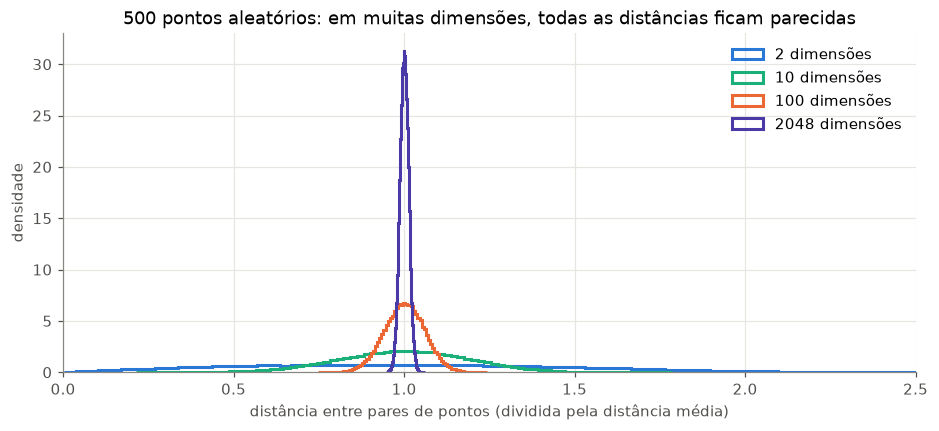

,dimensões,mais perto / mais longe
0,2,0.00
1,10,0.12
2,100,0.60
3,2048,0.89


In [5]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(10, 4))
linhas = []
for dim, cor in zip([2, 10, 100, 2048], [AZUL, VERDE, LARANJA, "#4a3aa7"]):
    pontos = torch.tensor(rng.random((500, dim)))
    dist = torch.cdist(pontos, pontos).numpy()[np.triu_indices(500, k=1)]
    ax.hist(dist / dist.mean(), bins=80, histtype="step", lw=2, color=cor, density=True, label=f"{dim} dimensões")
    linhas.append({"dimensões": dim, "mais perto / mais longe": f"{dist.min() / dist.max():.2f}"})
ax.set(xlabel="distância entre pares de pontos (dividida pela distância média)", ylabel="densidade",
       title="500 pontos aleatórios: em muitas dimensões, todas as distâncias ficam parecidas", xlim=(0, 2.5))
ax.legend(frameon=False)
plt.show()
pd.DataFrame(linhas)

Em 2 dimensões, há pares muito próximos e muito distantes. Em 2.048, quase todas as distâncias ficam perto da média:
o par mais próximo está a quase a mesma distância que o par mais distante.

A boa notícia: embeddings de dados reais **não** são pontos aleatórios. Eles ocupam uma região bem menor do espaço (como
uma folha de papel amassada dentro de uma sala), e os métodos de redução de dimensionalidade tentam "desamassar" essa
folha. Vamos comparar os três mais usados.

## 3.2 PCA (*Principal Component Analysis*)

A PCA procura as **direções de maior variação** dos dados. A 1ª componente é a direção em que os pontos mais se espalham;
a 2ª é a de maior variação **perpendicular** à primeira, e assim por diante. Projetar os dados nas 2 primeiras é como
tirar a "foto" mais informativa possível de um objeto 3D.

- **Linear**: cada componente é uma combinação (soma ponderada) das 2.048 dimensões.
- **Rápida e determinística**: mesmo resultado sempre.
- **Tem `transform`**: projeta pontos **novos** no mesmo mapa.
- **Interpretável**: diz quanto da variação total cada componente explica.
- **Limitação**: só enxerga estruturas **lineares**; grupos que se separam de forma curva podem ficar sobrepostos.

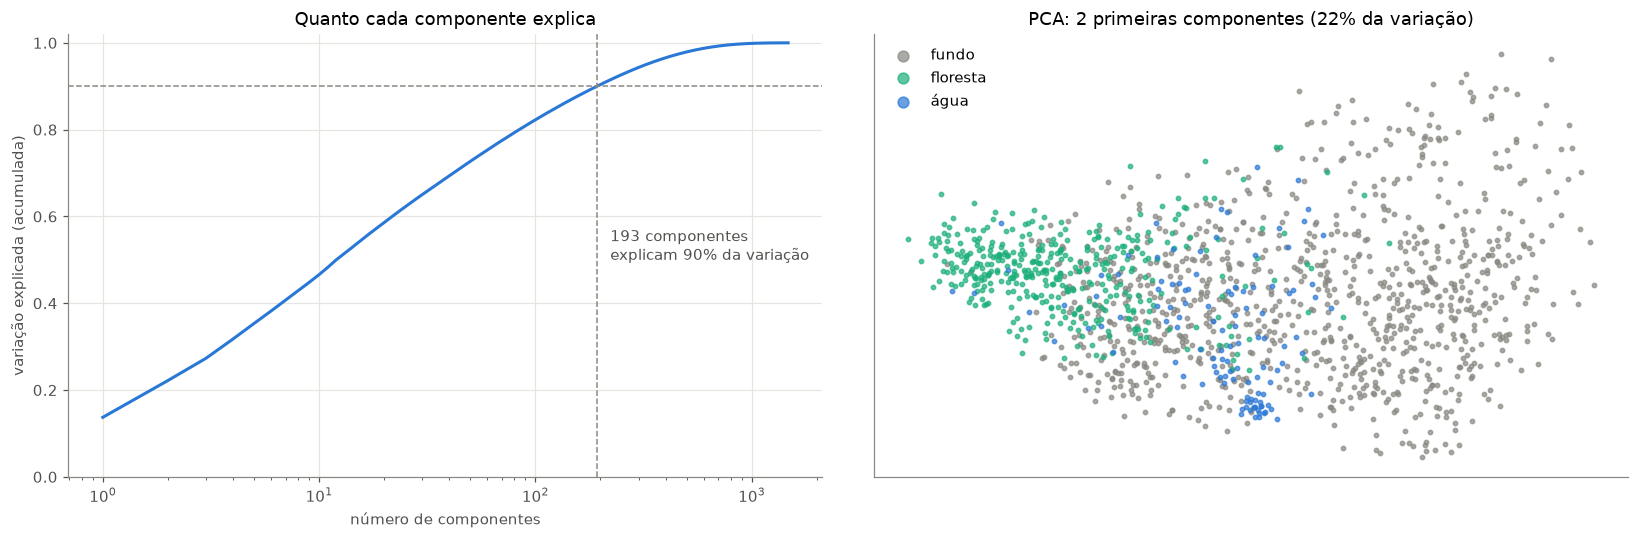

PCA em 0.2 s


In [7]:
from sklearn.decomposition import PCA

inicio = time.time()
pca = PCA().fit(embeddings.numpy())
xy_pca = pca.transform(embeddings.numpy())[:, :2]
tempo_pca = time.time() - inicio
var_acum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(var_acum, 0.9)) + 1

classes_presentes = np.unique(classes_tile)
cores_pontos = {0: "#898781", 1: CORES_LC[1], 2: CORES_LC[2], 3: CORES_LC[3], 4: CORES_LC[4]}   # fundo em cinza escuro

def desenha_projecao(ax, xy, titulo):
    for c in classes_presentes:
        m = classes_tile == c
        ax.scatter(xy[m, 0], xy[m, 1], s=8, color=cores_pontos[c], alpha=0.7, label=NOMES_LC[c])
    ax.set(title=titulo, xticks=[], yticks=[])
    ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(np.arange(1, len(var_acum) + 1), var_acum, color=AZUL, lw=2)
axes[0].axhline(0.9, color=CINZA, ls="--", lw=1)
axes[0].axvline(n90, color=CINZA, ls="--", lw=1)
axes[0].text(n90 * 1.15, 0.5, f"{n90} componentes\nexplicam 90% da variação", color=TINTA)
axes[0].set(xscale="log", xlabel="número de componentes", ylabel="variação explicada (acumulada)",
            title="Quanto cada componente explica", ylim=(0, 1.02))
desenha_projecao(axes[1], xy_pca, f"PCA: 2 primeiras componentes ({var_acum[1]:.0%} da variação)")
axes[1].legend(frameon=False, markerscale=2.5)
plt.tight_layout()
plt.show()
print(f"PCA em {tempo_pca:.1f} s")

**Leitura:** as 2 primeiras componentes explicam só uma pequena parte da variação total; para guardar 90% da informação
precisamos de cerca de 200 componentes, bem menos que 2.048. No mapa, a floresta e a água já se separam do
fundo, mas os grupos se sobrepõem bastante: a estrutura dos embeddings não é linear.

> Uso prático: a PCA raramente é o mapa final, mas é um ótimo **primeiro passo**: reduzir de 2.048 para ~50 dimensões
> tira ruído e acelera o t-SNE e o UMAP.

## 3.3 t-SNE (*t-distributed Stochastic Neighbor Embedding*)

O t-SNE (2008) não tenta preservar distâncias, e sim **vizinhanças**. Em resumo:

1. no espaço original, calcula para cada ponto a **probabilidade** de cada outro ser seu vizinho (vizinhos próximos = alta probabilidade);
2. espalha os pontos em 2D e os move até que as probabilidades em 2D fiquem **parecidas** com as originais.

- **Não linear**: consegue "desamassar" a folha de papel.
- **Ótimo para grupos locais**: pontos vizinhos no espaço original continuam vizinhos no mapa.
- **Cuidado**: o **tamanho** dos grupos e a **distância entre grupos** no mapa **não têm significado**; o resultado muda
  com a semente aleatória; é lento para muitos pontos; **não tem `transform`** para pontos novos.
- **Parâmetro principal**: a `perplexity`, aproximadamente o número de vizinhos que cada ponto "considera" (5 a 50).

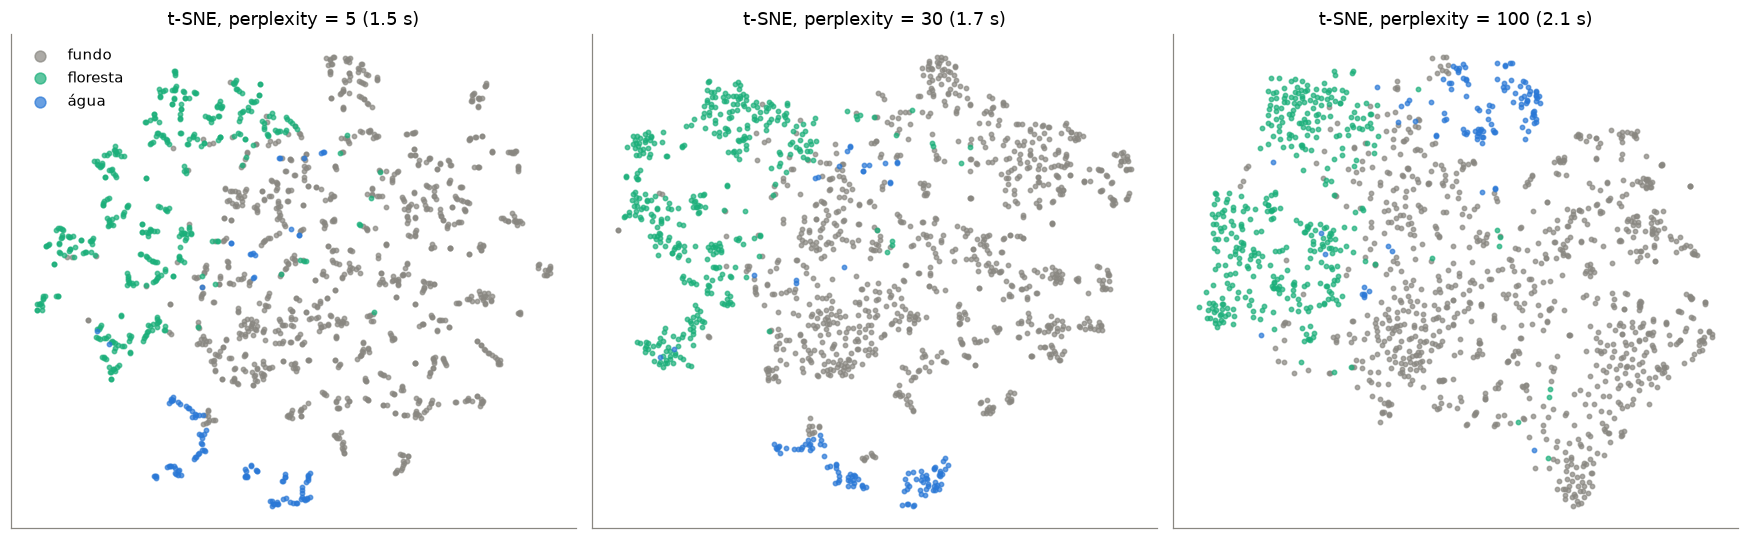

In [8]:
from sklearn.manifold import TSNE

emb_pca50 = PCA(n_components=50, random_state=0).fit_transform(embeddings.numpy())   # PCA antes: mais rápido e menos ruído

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, perp in zip(axes, [5, 30, 100]):
    inicio = time.time()
    xy = TSNE(n_components=2, perplexity=perp, init="pca", random_state=0).fit_transform(emb_pca50)
    if perp == 30:
        xy_tsne, tempo_tsne = xy, time.time() - inicio
    desenha_projecao(ax, xy, f"t-SNE, perplexity = {perp} ({time.time() - inicio:.1f} s)")
axes[0].legend(frameon=False, markerscale=2.5)
plt.tight_layout()
plt.show()

Com `perplexity` pequena, o t-SNE quebra os dados em muitos grupinhos (só olha os vizinhos imediatos); com
`perplexity` grande, os grupos ficam mais coesos e a organização geral aparece melhor. Não existe valor "certo":
vale testar alguns.

## 3.4 UMAP (*Uniform Manifold Approximation and Projection*)

O UMAP (2018) tem uma ideia parecida com a do t-SNE, com outra matemática:

1. constrói um **grafo de vizinhos** no espaço original (cada ponto ligado aos seus `n_neighbors` mais próximos);
2. procura um desenho em 2D cujo grafo seja o mais parecido possível com o original.

- **Não linear**, como o t-SNE, e em geral **mais rápido** para muitos pontos.
- Costuma preservar melhor a **estrutura global** (a posição relativa dos grupos), embora ainda não se deva levar as
  distâncias do mapa ao pé da letra.
- **Tem `transform`**: projeta pontos novos no mapa já construído.
- **Parâmetros principais**: `n_neighbors` (local × global, como a `perplexity`) e `min_dist` (o quanto os pontos podem se
  amontoar no mapa).

(Na primeira execução, o UMAP leva alguns segundos a mais para compilar o código.)

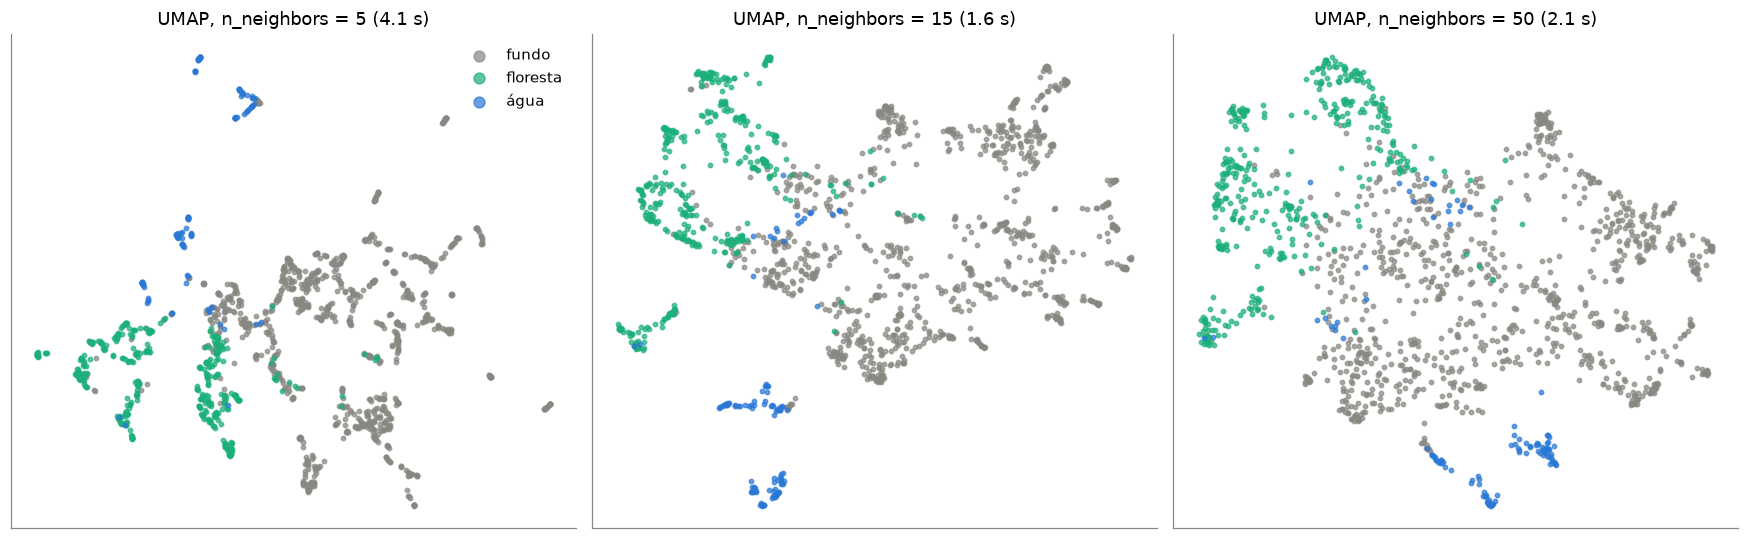

In [9]:
import umap

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, viz in zip(axes, [5, 15, 50]):
    inicio = time.time()
    xy = umap.UMAP(n_neighbors=viz, min_dist=0.1, random_state=0).fit_transform(emb_pca50)
    if viz == 15:
        xy_umap, tempo_umap = xy, time.time() - inicio
    desenha_projecao(ax, xy, f"UMAP, n_neighbors = {viz} ({time.time() - inicio:.1f} s)")
axes[0].legend(frameon=False, markerscale=2.5)
plt.tight_layout()
plt.show()

## 3.5 Comparando os três

Além de olhar, dá para **medir** a qualidade de um mapa:

- **Confiabilidade** (*trustworthiness*, de 0 a 1): dos vizinhos de um ponto no mapa 2D, quantos também eram vizinhos no
  espaço original? Valores perto de 1 = o mapa não inventa vizinhanças.
- **k-NN no mapa**: classificamos a classe dos pedaços das fotos de teste usando só as 2 coordenadas do mapa. Se os
  grupos do mapa correspondem às classes, o k-NN acerta.

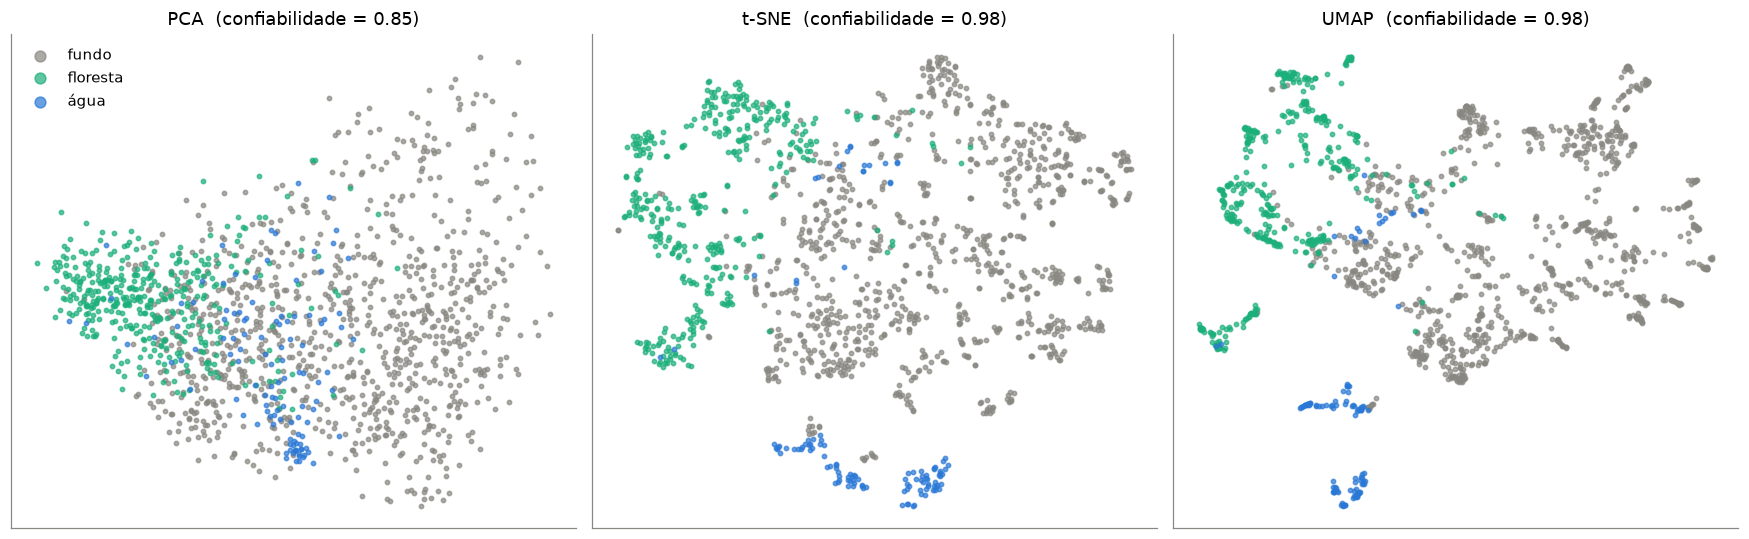

,tempo (s),confiabilidade (10 vizinhos),k-NN no mapa 2D (acurácia balanceada)
PCA,0.185,0.849,0.581
t-SNE,1.672,0.983,0.756
UMAP,1.597,0.978,0.753
sem reduzir (2.048 dimensões),—,—,0.772


In [10]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score

treino_t, teste_t = split_tile == "train", split_tile == "teste"

def knn_balanceado(X):
    knn = KNeighborsClassifier(n_neighbors=5).fit(X[treino_t], classes_tile[treino_t])
    return balanced_accuracy_score(classes_tile[teste_t], knn.predict(X[teste_t]))

mapas = {"PCA": (xy_pca, tempo_pca), "t-SNE": (xy_tsne, tempo_tsne), "UMAP": (xy_umap, tempo_umap)}
comparacao = pd.DataFrame({
    nome: {"tempo (s)": tempo, "confiabilidade (10 vizinhos)": trustworthiness(emb_pca50, xy, n_neighbors=10),
           "k-NN no mapa 2D (acurácia balanceada)": knn_balanceado(xy)}
    for nome, (xy, tempo) in mapas.items()
}).T
comparacao.loc["sem reduzir (2.048 dimensões)", "k-NN no mapa 2D (acurácia balanceada)"] = knn_balanceado(embeddings.numpy())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (nome, (xy, _)) in zip(axes, mapas.items()):
    desenha_projecao(ax, xy, f"{nome}  (confiabilidade = {comparacao.loc[nome, 'confiabilidade (10 vizinhos)']:.2f})")
axes[0].legend(frameon=False, markerscale=2.5)
plt.tight_layout()
plt.show()
comparacao.round(3).fillna("—")

**Leitura:**

- **t-SNE e UMAP** preservam quase todas as vizinhanças (confiabilidade perto de 1) e, com apenas **2 números** por pedaço,
  o k-NN acerta quase tanto quanto com os **2.048** originais. Os grupos que vemos no mapa são reais.
- A **PCA em 2D** perde muito: a confiabilidade cai e o k-NN piora bastante. Duas direções lineares não bastam para
  representar esses embeddings (lembre: as 2 primeiras componentes explicam só ~22% da variação).
- Com ~1.500 pontos, t-SNE e UMAP levam tempos parecidos; com dezenas de milhares, o UMAP costuma ser bem mais rápido.
- Um cuidado com o k-NN no mapa do **t-SNE**: o mapa foi construído já com os pontos de teste (o t-SNE não tem `transform`),
  então esse número é um pouco otimista. Com o UMAP daria para ajustar o mapa só com o treino e projetar o teste depois
  (exercício 3).

| | PCA | t-SNE | UMAP |
|---|---|---|---|
| Tipo | linear | não linear | não linear |
| Preserva | variância global | vizinhanças locais | vizinhanças locais e parte da estrutura global |
| Velocidade | muito rápida | lenta para muitos pontos | rápida |
| Determinística? | sim | não (depende da semente) | não (depende da semente) |
| Projeta pontos novos (`transform`)? | sim | **não** | sim |
| Distâncias no mapa têm significado? | sim (aproximadas) | **não** entre grupos | só aproximadamente |
| Use para | pré-processar, comprimir, interpretar | visualizar grupos | visualizar grupos, pré-processar para clustering |

# Parte 4 — Explorando os embeddings de forma interativa

Um mapa só faz sentido quando conseguimos ver **o que** cada ponto representa. Abaixo, um mapa interativo feito com o
**Bokeh**, que funciona no Jupyter, no VS Code e também na página publicada do curso (a interação roda no navegador):

- **passe o mouse** sobre um ponto para ver a imagem;
- desenhe um **laço** (*lasso*) em volta de um grupo de pontos: o painel da direita mostra as imagens selecionadas e
  quantas são de cada classe;
- segure **Shift** para somar seleções; clique duas vezes em uma área vazia para limpar;
- troque a projeção (UMAP, t-SNE, PCA) nos botões acima do mapa.

In [11]:
from bokeh.plotting import figure, show, output_notebook
from bokeh.models import ColumnDataSource, CustomJS, Div, HoverTool, RadioButtonGroup
from bokeh.layouts import column, row

output_notebook(hide_banner=True)

def miniatura(tile, lado=64):
    """Converte um pedaço de imagem em uma miniatura JPEG embutida (data URI), para o navegador mostrar."""
    img = Image.fromarray((tile.permute(1, 2, 0).numpy() * 255).astype("uint8")).resize((lado, lado))
    buffer = BytesIO()
    img.save(buffer, format="JPEG", quality=70)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()

fonte = ColumnDataSource(dict(
    x=xy_umap[:, 0], y=xy_umap[:, 1],
    x_umap=xy_umap[:, 0], y_umap=xy_umap[:, 1],
    x_tsne=xy_tsne[:, 0], y_tsne=xy_tsne[:, 1],
    x_pca=xy_pca[:, 0], y_pca=xy_pca[:, 1],
    classe=[NOMES_LC[c] for c in classes_tile],
    cor=[cores_pontos[c] for c in classes_tile],
    foto=[i for i, _ in origem],
    img=[miniatura(t) for t in tiles],
))

mapa = figure(width=620, height=560, tools="lasso_select,box_select,pan,wheel_zoom,reset",
              active_drag="lasso_select", title="Embeddings da ResNet-50 (cada ponto é um pedaço de imagem)",
              toolbar_location="above")
mapa.scatter("x", "y", source=fonte, size=6, color="cor", alpha=0.75, legend_field="classe",
             selection_color="cor", nonselection_alpha=0.12)
mapa.add_tools(HoverTool(tooltips='<div><img src="@img" width="96" height="96"><br><b>@classe</b><br>@foto</div>'))
mapa.legend.location = "top_left"
mapa.xaxis.visible = mapa.yaxis.visible = False
mapa.grid.visible = False

painel = Div(text="<i>Desenhe um laço em volta de alguns pontos para ver as imagens.</i>", width=430, height=560,
             styles={"overflow-y": "auto"})
fonte.selected.js_on_change("indices", CustomJS(args=dict(fonte=fonte, painel=painel), code="""
    const idx = fonte.selected.indices;
    const d = fonte.data;
    if (idx.length === 0) { painel.text = "<i>Nenhum ponto selecionado.</i>"; return; }
    const contagem = {};
    for (const i of idx) contagem[d.classe[i]] = (contagem[d.classe[i]] || 0) + 1;
    let html = `<b>${idx.length} imagens selecionadas</b><br>`;
    html += Object.entries(contagem).map(([c, n]) => `${c}: ${n} (${Math.round(100 * n / idx.length)}%)`).join(" · ");
    html += `<div style="margin-top:6px">`;
    for (const i of idx.slice(0, 120)) html += `<img src="${d.img[i]}" width="64" height="64" style="margin:1px" title="${d.classe[i]}">`;
    if (idx.length > 120) html += `<br><i>... e mais ${idx.length - 120}</i>`;
    painel.text = html + "</div>";
"""))

botoes = RadioButtonGroup(labels=["UMAP", "t-SNE", "PCA"], active=0)
botoes.js_on_change("active", CustomJS(args=dict(fonte=fonte), code="""
    const chave = ["umap", "tsne", "pca"][this.active];
    const d = fonte.data;
    d.x = d["x_" + chave]; d.y = d["y_" + chave];
    fonte.selected.indices = [];
    fonte.change.emit();
"""))

show(column(botoes, row(mapa, painel)))

**Sugestões de exploração:**

- Selecione os pontos de **fundo** que ficam em grupos separados. Você vai encontrar subgrupos bem definidos: plantações
  em linhas, solo exposto, gramados, áreas urbanas. O rótulo "fundo" junta coisas que a ResNet-50 enxerga como diferentes!
- Selecione os pontos de **água**: os dois grupos que aparecem correspondem a águas escuras e águas claras (esverdeadas).
- Procure pontos "fora do lugar" (uma floresta no meio do fundo, por exemplo) e passe o mouse: muitos são pedaços
  mistos, ou erros do próprio rótulo.

### Uma versão estática do mapa

Para impressão (ou se o mapa interativo não aparecer), o mesmo mapa UMAP com algumas imagens desenhadas sobre ele:

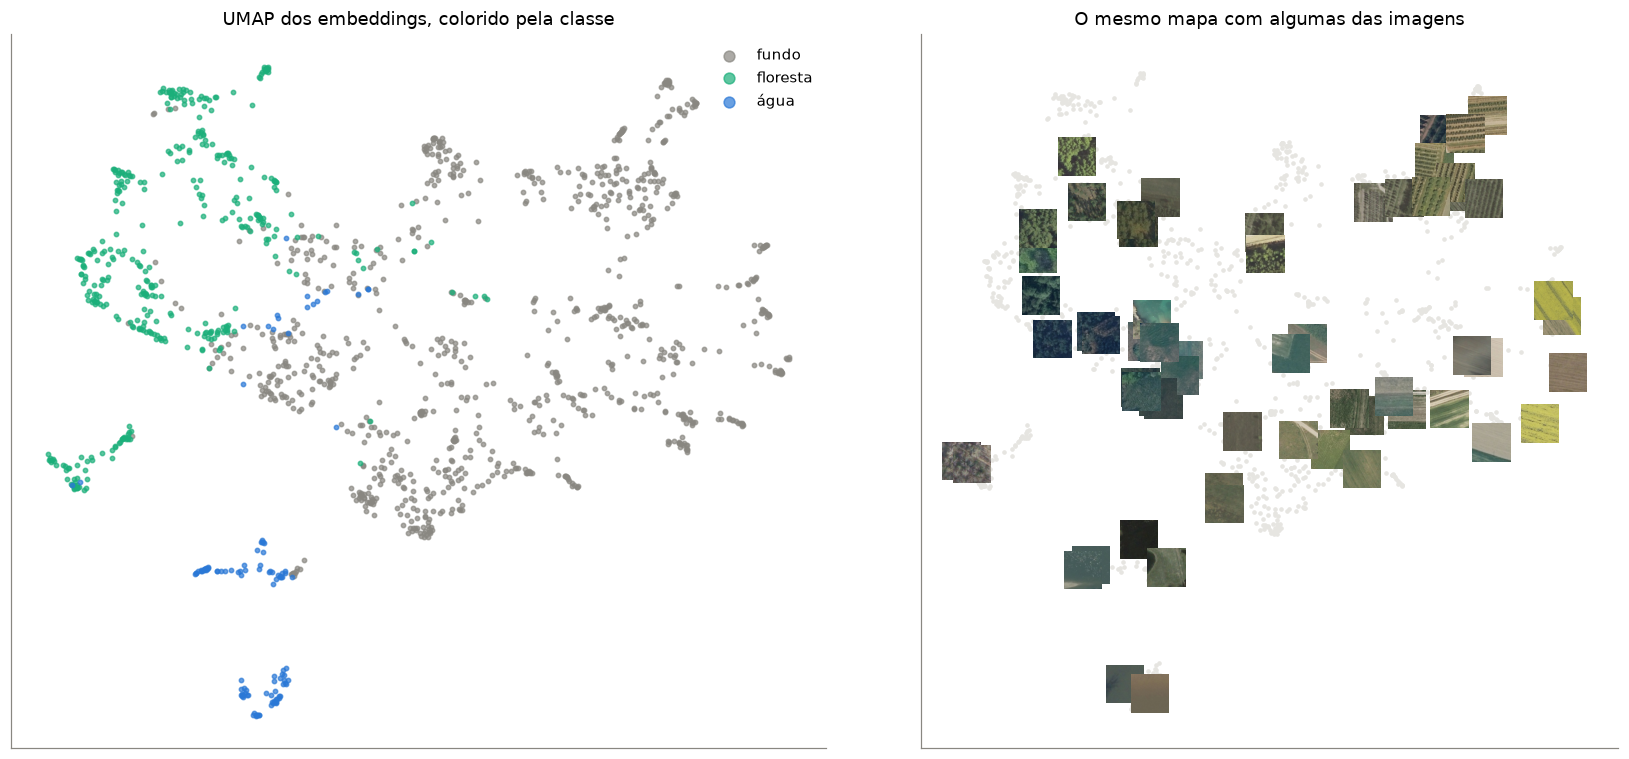

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), width_ratios=[1, 1.15])
desenha_projecao(axes[0], xy_umap, "UMAP dos embeddings, colorido pela classe")
axes[0].legend(frameon=False, markerscale=2.5)

gerador = np.random.default_rng(0)
meio = 0.03 * (xy_umap.max() - xy_umap.min())          # metade do lado de cada miniatura
axes[1].scatter(xy_umap[:, 0], xy_umap[:, 1], s=4, color="#e6e5e1")
for k in gerador.choice(len(tiles), 60, replace=False):
    caixa = [xy_umap[k, 0] - meio, xy_umap[k, 0] + meio, xy_umap[k, 1] - meio, xy_umap[k, 1] + meio]
    axes[1].imshow(tiles[k].permute(1, 2, 0), extent=caixa, zorder=3)
axes[1].set(title="O mesmo mapa com algumas das imagens", xticks=[], yticks=[],
            xlim=(xy_umap[:, 0].min() - 2 * meio, xy_umap[:, 0].max() + 2 * meio),
            ylim=(xy_umap[:, 1].min() - 2 * meio, xy_umap[:, 1].max() + 2 * meio))
axes[1].grid(False)
plt.tight_layout()
plt.show()

# Parte 5 — Similaridade de cosseno: buscando imagens parecidas

Se imagens parecidas têm embeddings próximos, dá para **buscar imagens parecidas** com uma conta simples. A medida
mais usada é a **similaridade de cosseno**: o cosseno do ângulo entre dois vetores (1 = mesma direção, 0 = sem relação).

$$\text{sim}(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|}$$

Para cada imagem de consulta, buscamos as 5 mais parecidas entre os pedaços de **outras** fotos (para não valer pedaços
vizinhos da mesma foto).

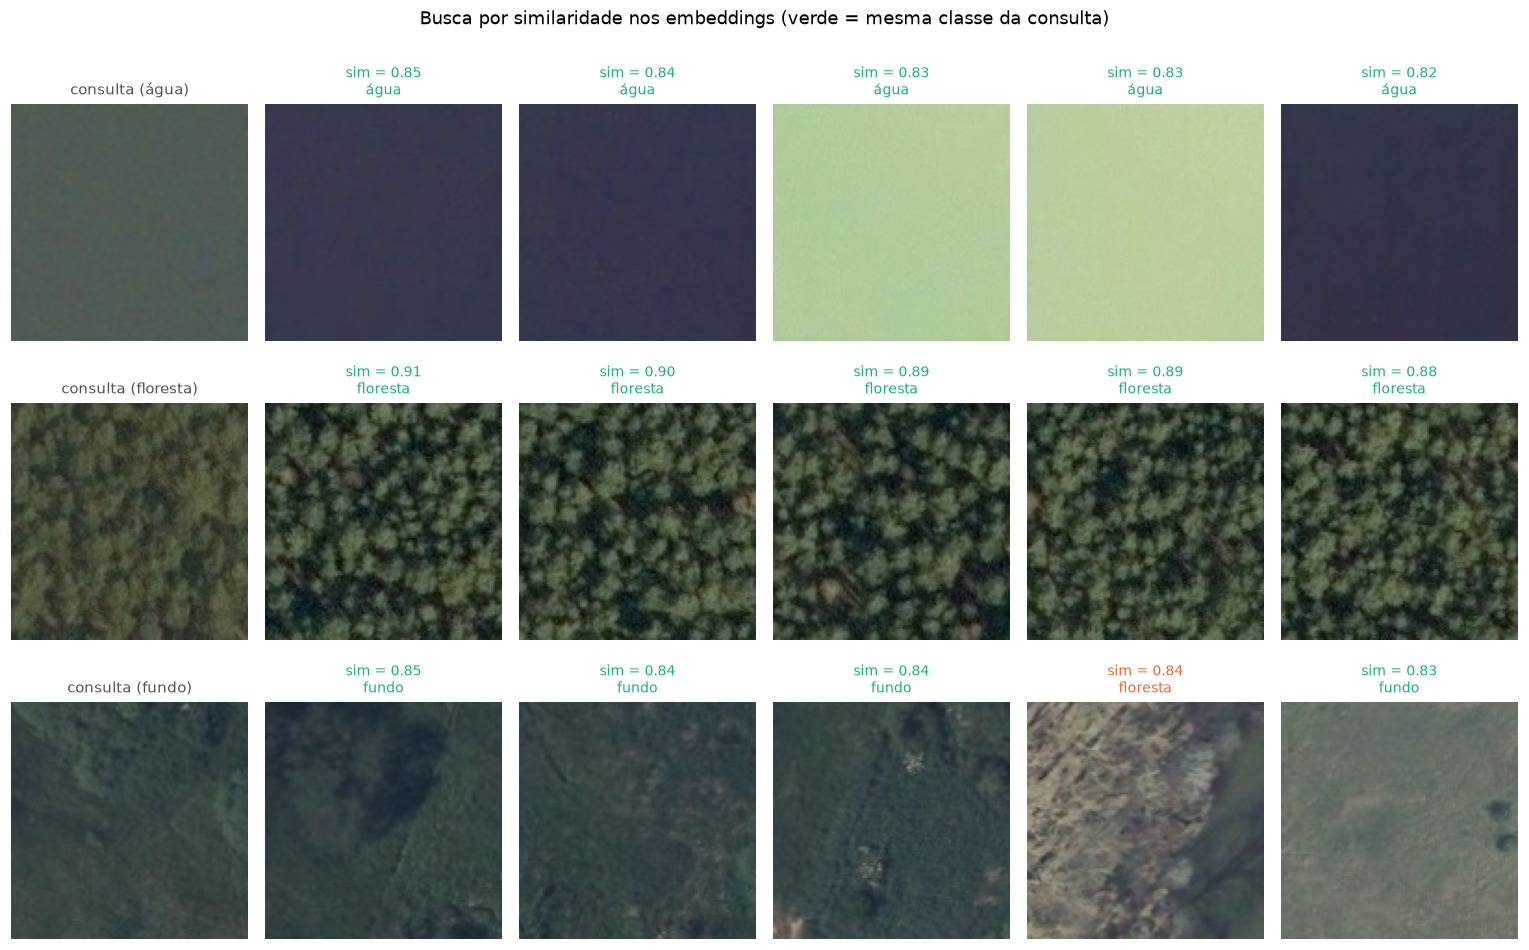

In [13]:
emb_norm = F.normalize(embeddings, dim=1)                 # vetores de comprimento 1: o produto escalar vira o cosseno
similaridade = emb_norm @ emb_norm.T                      # (N, N): a similaridade de cada par de pedaços
foto = np.array([i for i, _ in origem])

consultas = [int(np.flatnonzero(classes_tile == c)[3]) for c in [3, 2, 0]]      # água, floresta, fundo
fig, axes = plt.subplots(len(consultas), 6, figsize=(14, 2.95 * len(consultas)))
for linha, q in enumerate(consultas):
    s = similaridade[q].clone()
    s[torch.tensor(foto == foto[q])] = -1                 # ignora pedaços da mesma foto
    vizinhos = s.topk(5).indices
    axes[linha, 0].imshow(tiles[q].permute(1, 2, 0))
    axes[linha, 0].set_title(f"consulta ({NOMES_LC[classes_tile[q]]})", color=TINTA, fontsize=10)
    for k, v in enumerate(vizinhos):
        axes[linha, k + 1].imshow(tiles[v].permute(1, 2, 0))
        axes[linha, k + 1].set_title(f"sim = {s[v]:.2f}\n{NOMES_LC[classes_tile[v]]}", fontsize=9,
                                     color=VERDE if classes_tile[v] == classes_tile[q] else LARANJA)
    for ax in axes[linha]:
        ax.axis("off")
plt.suptitle("Busca por similaridade nos embeddings (verde = mesma classe da consulta)", y=1.0)
plt.tight_layout()
plt.show()

### Quão parecidas são as classes entre si?

Com a matriz de similaridade de todos os pares, podemos calcular a **similaridade média** entre os pedaços de cada par de
classes. Na diagonal, a similaridade **dentro** de cada classe; fora dela, **entre** classes.

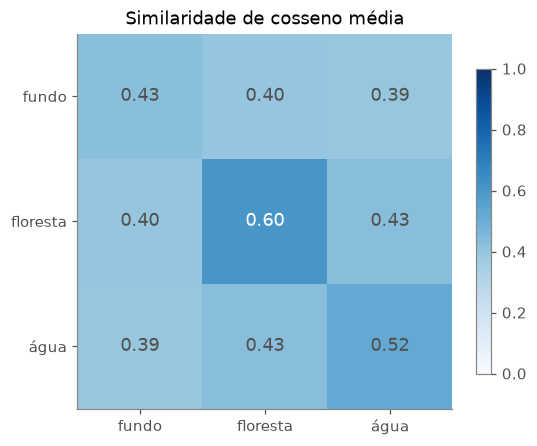

In [14]:
nomes_presentes = [NOMES_LC[c] for c in classes_presentes]
media_sim = np.zeros((len(classes_presentes), len(classes_presentes)))
for a, ca in enumerate(classes_presentes):
    for b, cb in enumerate(classes_presentes):
        bloco = similaridade[np.ix_(classes_tile == ca, classes_tile == cb)]
        if ca == cb:                                    # dentro da classe: ignora a diagonal (cada pedaço com ele mesmo)
            n = bloco.shape[0]
            media_sim[a, b] = (bloco.sum() - n) / (n * (n - 1))
        else:
            media_sim[a, b] = bloco.mean()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(media_sim, cmap="Blues", vmin=0, vmax=1)
for a in range(len(classes_presentes)):
    for b in range(len(classes_presentes)):
        ax.text(b, a, f"{media_sim[a, b]:.2f}", ha="center", va="center", fontsize=12,
                color="white" if media_sim[a, b] > 0.6 else TINTA)
ax.set(xticks=range(len(nomes_presentes)), xticklabels=nomes_presentes, yticks=range(len(nomes_presentes)),
       yticklabels=nomes_presentes, title="Similaridade de cosseno média")
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

**Leitura:** a similaridade **dentro** de cada classe (diagonal) é maior que **entre** classes, e é isso que faz a busca
por similaridade e o k-NN funcionarem. A floresta é a classe mais "homogênea": copas de árvores vistas de cima se parecem
muito. O fundo é a mais variada, como vimos no mapa interativo.

# Parte 6 — Embeddings como features prontas

Um embedding também é uma ótima **tabela de features** para os métodos de Machine Learning clássico. Com um simples
**k-vizinhos mais próximos** (k-NN) sobre os embeddings, sem treinar a rede, classificamos a classe dominante dos pedaços
das fotos de **teste** usando só os pedaços das fotos de **treino**:

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

treino_t, teste_t = split_tile == "train", split_tile == "teste"
knn = KNeighborsClassifier(n_neighbors=5, metric="cosine").fit(embeddings[treino_t].numpy(), classes_tile[treino_t])
pred_knn = knn.predict(embeddings[teste_t].numpy())
maioria = np.bincount(classes_tile[treino_t]).argmax()

print(f"pedaços de treino: {treino_t.sum()}, de teste: {teste_t.sum()}")
print(f"k-NN nos embeddings:  acurácia = {accuracy_score(classes_tile[teste_t], pred_knn):.1%}   "
      f"acurácia balanceada = {balanced_accuracy_score(classes_tile[teste_t], pred_knn):.1%}")
print(f"chutar sempre '{NOMES_LC[maioria]}': acurácia = {(classes_tile[teste_t] == maioria).mean():.1%}")

pedaços de treino: 1023, de teste: 451
k-NN nos embeddings:  acurácia = 87.1%   acurácia balanceada = 78.5%
chutar sempre 'fundo': acurácia = 61.9%


**Leitura:** sem treinar a rede e sem nenhum ajuste, um k-NN sobre os embeddings acerta muito mais do que chutar sempre a
classe mais comum. A **acurácia balanceada** (a média do acerto em cada classe) mostra que ele também acerta as classes
menores, não só o fundo. É por isso que embeddings de modelos pré-treinados são tão usados: transformam imagens em
tabelas de features prontas para os métodos clássicos das aulas de Machine Learning.

# Parte 7 — Embeddings em observação da Terra

A mesma ideia está mudando o sensoriamento remoto: em vez de baixar e processar imagens brutas, já é possível usar
**embeddings prontos**, calculados por modelos de fundação. Exemplos:

- o **Satellite Embedding** do Google (modelo AlphaEarth Foundations, 2025), disponível no Earth Engine: um vetor de 64
  números por pixel de 10 m, para cada ano, que resume as observações de vários satélites;
- os modelos **Clay** e **Prithvi**, que geram embeddings de recortes de imagens de satélite, disponíveis no Hugging Face.

Com embeddings, tarefas como "encontre áreas parecidas com esta", agrupar regiões ou treinar um classificador com
poucos exemplos ficam rápidas e baratas. Na aula 7 vimos que os Transformers produzem um embedding para **cada**
patch da imagem: a PCA das features do DINOv2 que fizemos lá era exatamente uma redução de
dimensionalidade de embeddings, como as desta aula.

# Resumo

- Um **embedding** é um vetor que resume um objeto (imagem, pedaço de imagem, texto); objetos parecidos ficam próximos.
- Redes pré-treinadas, como a ResNet-50, geram embeddings úteis **sem treino adicional**.
- Em muitas dimensões, distâncias ficam parecidas e não dá para visualizar: daí a **redução de dimensionalidade**.

| Método | Ano | Ideia | Quando usar |
|---|---|---|---|
| **PCA** | 1901 / 1933 | direções de maior variância (linear) | comprimir, tirar ruído, pré-processar, interpretar |
| **t-SNE** | 2008 | preservar as vizinhanças (probabilidades) | visualizar grupos; não interpretar distâncias entre grupos |
| **UMAP** | 2018 | preservar um grafo de vizinhos | visualizar grupos, projetar pontos novos, pré-processar para clustering |

- A **similaridade de cosseno** mede o quanto dois embeddings apontam na mesma direção: é a base da busca por imagens parecidas.
- Embeddings são **features prontas** para k-NN, regressão logística, Random Forest e clustering.

### Exercícios

1. Na Parte 6, troque os embeddings da ResNet-50 pelos **pixels brutos** dos pedaços (`tiles.flatten(1)`). O k-NN fica
   melhor ou pior? O que isso diz sobre os embeddings?
2. Rode o t-SNE com 3 sementes diferentes (`random_state`). Os grupos mudam de lugar? E o que continua igual?
3. Use o `transform` do UMAP para projetar no mapa os pedaços das fotos de teste, ajustando o UMAP só com os de treino.
   Os pontos de teste caem nos grupos certos?
4. No mapa interativo, selecione um subgrupo de **fundo** e descreva o que as imagens têm em comum. Quantos "tipos" de
   fundo você encontra?
5. Aplique o **K-means** (aula de aprendizado não supervisionado) nos embeddings reduzidos pela PCA para 50 dimensões.
   Os grupos encontrados correspondem às classes?
6. Troque a ResNet-50 pelo **DINOv2** da aula 7 (`dino.forward_features(...)[:, 0]`, o token [CLS]) para gerar os
   embeddings. O mapa e o k-NN ficam melhores?